<a href="https://colab.research.google.com/github/nikita082000/DTEY/blob/%D0%9C%D0%9D/%D0%9B%D0%A04_%D0%9D%D1%96%D0%BA%D0%B8%D1%82%D0%B5%D0%BD%D0%BA%D0%BE_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [2]:
!pip install -q kagglehub

import kagglehub
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [3]:
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")

df = pd.read_csv(
    os.path.join(path, "CarPrice_Assignment.csv")
)

print("Розмір:", df.shape)
print("\nНазви стовпців:")
print(df.columns.tolist())

print("\nТипи даних:")
print(df.dtypes)

Using Colab cache for faster access to the 'car-price-prediction' dataset.
Розмір: (205, 26)

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [4]:
print("Пропущені значення:")
print(df.isna().sum())

print("\nПовні дублікати:")
print(df.duplicated().sum())

print("\nДублікати без урахування car_ID:")
print(df.drop(columns="car_ID").duplicated().sum())

print("\nКількість унікальних значень:")
print(df.nunique())

Пропущені значення:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

Повні дублікати:
0

Дублікати без урахування car_ID:
0

Кількість унікальних значень:
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight           

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [5]:
car_ids = df["car_ID"].copy()

data = df.drop(columns="car_ID")

print("Збережено car_ID:", len(car_ids))
print("Ознаки для подальшої роботи:")
print(data.columns.tolist())

Збережено car_ID: 205
Ознаки для подальшої роботи:
['symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


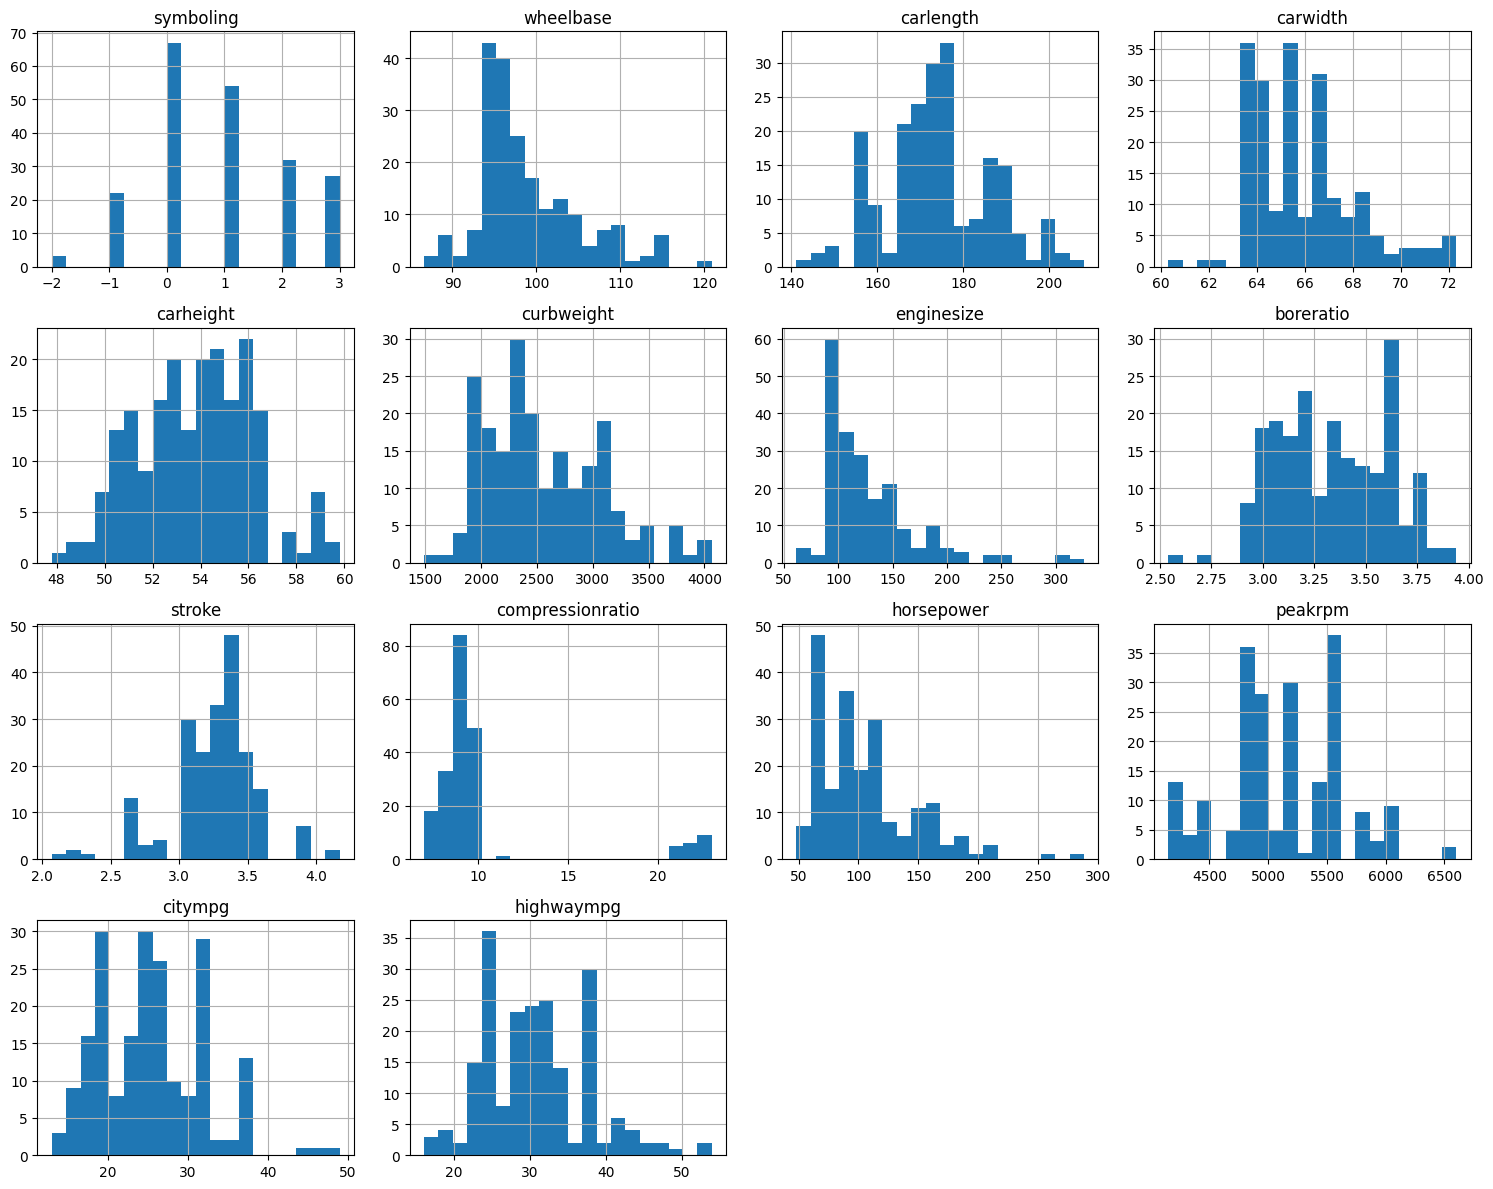

In [6]:
numeric_features = data.drop(columns="price").select_dtypes(
    include=np.number
).columns

data[numeric_features].hist(
    figsize=(15, 12),
    bins=20
)

plt.tight_layout()
plt.show()

In [7]:
skewness = data[numeric_features].skew()

skewness_table = pd.DataFrame({
    "Feature": skewness.index,
    "Skewness": skewness.values,
    "Abs_Skewness": skewness.abs().values
}).sort_values(
    "Abs_Skewness",
    ascending=False
)

skewness_table

,Feature,Skewness,Abs_Skewness
9,compressionratio,2.610862,2.610862
6,enginesize,1.947655,1.947655
10,horsepower,1.405310,1.405310
1,wheelbase,1.050214,1.050214
3,carwidth,0.904003,0.904003
8,stroke,-0.689705,0.689705
5,curbweight,0.681398,0.681398
12,citympg,0.663704,0.663704
13,highwaympg,0.539997,0.539997
0,symboling,0.211072,0.211072


Частина числових ознак має помітну асиметрію розподілу. Найбільшу асиметрію мають compressionratio (2.61), enginesize (1.95), horsepower (1.41) та wheelbase (1.05). Для зменшення асиметрії неперервних числових ознак надалі буде використано перетворення Yeo–Johnson.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [8]:
X = data.drop(columns="price")
y = data["price"]

In [9]:
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X,
    y,
    car_ids,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (164, 24)
X_test: (41, 24)
y_train: (164,)
y_test: (41,)


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [10]:
continuous_features = [
    col for col in X_train.select_dtypes(include=np.number).columns
    if col != "symboling"
]

In [11]:
outlier_info = []
iqr_bounds = {}

for col in continuous_features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    iqr_bounds[col] = (lower, upper)

    count = (
        (X_train[col] < lower) |
        (X_train[col] > upper)
    ).sum()

    outlier_info.append({
        "Feature": col,
        "Outliers": count
    })

outlier_table = pd.DataFrame(outlier_info)

outlier_table

,Feature,Outliers
0,wheelbase,6
1,carlength,0
2,carwidth,10
3,carheight,0
4,curbweight,0
5,enginesize,7
6,boreratio,1
7,stroke,16
8,compressionratio,20
9,horsepower,7


In [12]:
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

for col, (lower, upper) in iqr_bounds.items():
    X_train_clean[col] = X_train_clean[col].clip(
        lower=lower,
        upper=upper
    )

    X_test_clean[col] = X_test_clean[col].clip(
        lower=lower,
        upper=upper
    )

Потенційні викиди було визначено методом IQR лише за навчальною вибіркою. Оскільки набір даних невеликий, рядки не видалялися, а крайні значення були обмежені відповідними IQR-межами. До test застосовано ті самі межі, що були отримані на train.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


In [13]:
corr_data = X_train_clean.select_dtypes(
    include=np.number
).copy()

corr_data["price"] = y_train

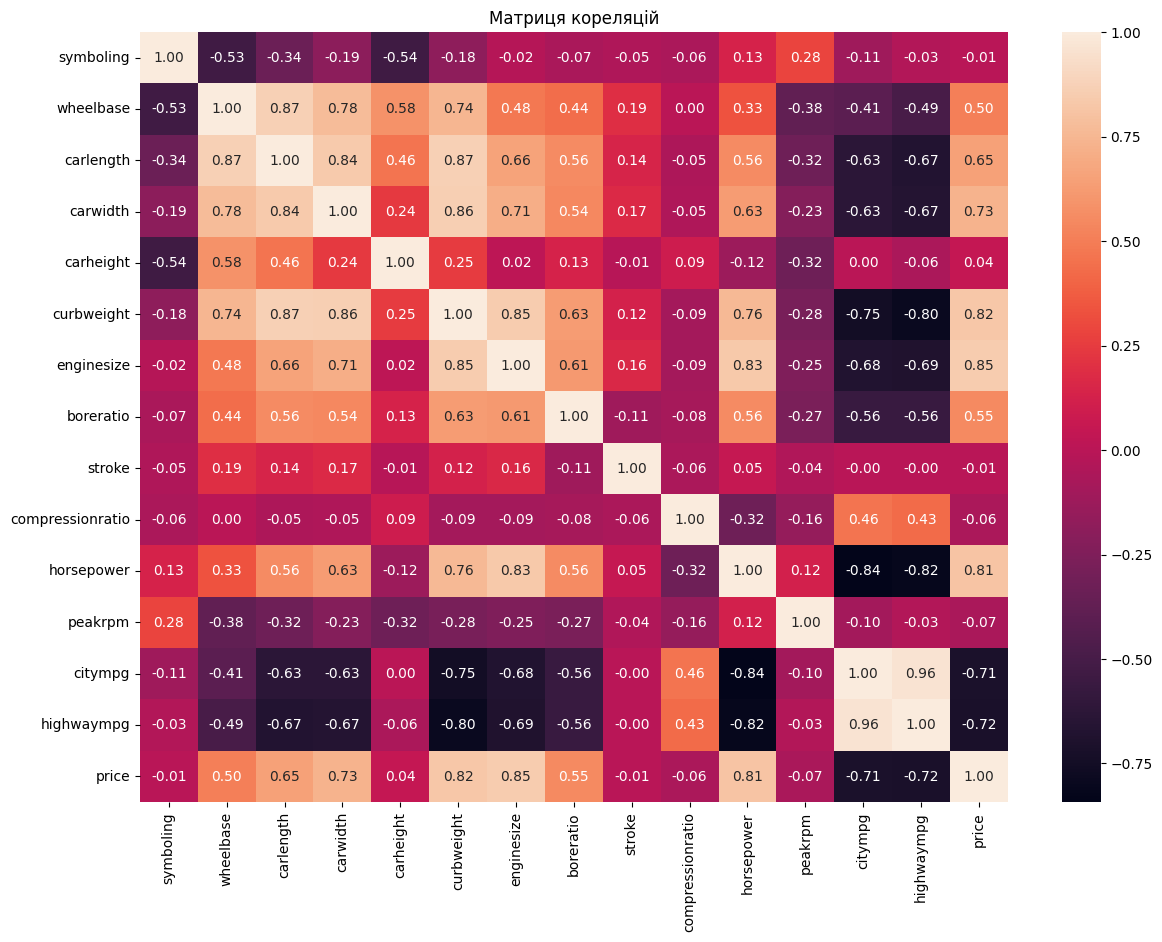

In [14]:
correlation = corr_data.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Матриця кореляцій")

plt.show()

In [15]:
feature_corr = correlation.drop(
    index="price",
    columns="price"
)

strong_pairs = []

columns = feature_corr.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        r = feature_corr.iloc[i, j]

        if abs(r) > 0.85:
            strong_pairs.append({
                "Feature 1": columns[i],
                "Feature 2": columns[j],
                "Correlation": r
            })

strong_pairs = pd.DataFrame(strong_pairs)

strong_pairs

,Feature 1,Feature 2,Correlation
0,wheelbase,carlength,0.867043
1,carlength,curbweight,0.865988
2,carwidth,curbweight,0.858047
3,citympg,highwaympg,0.963620


In [16]:
target_corr = correlation["price"].drop("price").abs()

features_to_drop = set()

for _, row in strong_pairs.sort_values(
    "Correlation",
    key=abs,
    ascending=False
).iterrows():

    f1 = row["Feature 1"]
    f2 = row["Feature 2"]

    if f1 in features_to_drop or f2 in features_to_drop:
        continue

    if target_corr[f1] >= target_corr[f2]:
        features_to_drop.add(f2)
    else:
        features_to_drop.add(f1)

features_to_drop = sorted(features_to_drop)

print("Ознаки для видалення:")
print(features_to_drop)

Ознаки для видалення:
['carlength', 'carwidth', 'citympg', 'wheelbase']


In [17]:
X_train_selected = X_train_clean.drop(
    columns=features_to_drop
)

X_test_selected = X_test_clean.drop(
    columns=features_to_drop
)

print("Train:", X_train_selected.shape)
print("Test:", X_test_selected.shape)

Train: (164, 20)
Test: (41, 20)


Ознаки із сильною взаємною кореляцією |r| > 0.85 були проаналізовані за навчальною вибіркою. У кожній сильно корельованій парі залишалась ознака, що мала сильніший абсолютний зв'язок із price. Із test було видалено той самий набір ознак.

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [18]:
continuous_features = [
    col for col in X_train_selected.select_dtypes(
        include=np.number
    ).columns
    if col != "symboling"
]

symboling_features = ["symboling"]

categorical_features = X_train_selected.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Неперервні числові:")
print(continuous_features)

print("\nДискретна числова:")
print(symboling_features)

print("\nКатегоріальні:")
print(categorical_features)

Неперервні числові:
['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']

Дискретна числова:
['symboling']

Категоріальні:
['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']


In [19]:
continuous_pipeline = Pipeline([
    (
        "yeo_johnson",
        PowerTransformer(
            method="yeo-johnson",
            standardize=False
        )
    ),
    (
        "scaler",
        StandardScaler()
    )
])

In [20]:
symboling_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

In [21]:
categorical_pipeline = Pipeline([
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

In [22]:
preprocessor = ColumnTransformer([
    (
        "continuous",
        continuous_pipeline,
        continuous_features
    ),
    (
        "symboling",
        symboling_pipeline,
        symboling_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [23]:
skew_before = X_train_selected[
    continuous_features
].skew()

In [24]:
continuous_check = Pipeline([
    (
        "yeo_johnson",
        PowerTransformer(
            method="yeo-johnson",
            standardize=False
        )
    ),
    (
        "scaler",
        StandardScaler()
    )
])

transformed_train = continuous_check.fit_transform(
    X_train_selected[continuous_features]
)

In [25]:
transformed_train = pd.DataFrame(
    transformed_train,
    columns=continuous_features,
    index=X_train_selected.index
)

skew_after = transformed_train.skew()

In [26]:
skew_comparison = pd.DataFrame({
    "Before": skew_before,
    "After": skew_after
})

skew_comparison

,Before,After
carheight,0.028154,-0.005170
curbweight,0.712433,0.049894
enginesize,0.962394,0.044834
boreratio,0.062963,-0.005941
stroke,-0.397600,0.015846
compressionratio,0.055710,0.004872
horsepower,0.850735,0.066280
peakrpm,0.039773,-0.003589
highwaympg,0.243761,-0.012188


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [27]:
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

In [28]:
models = {
    "Linear Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", LinearRegression())
    ]),

    "Ridge": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", Ridge())
    ]),

    "Lasso": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", Lasso(max_iter=10000))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            random_state=42
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", GradientBoostingRegressor(
            random_state=42
        ))
    ]),

    "SVR": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", SVR())
    ])
}

In [29]:
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_selected, y_train)

    y_pred = model.predict(X_test_selected)
    predictions[name] = y_pred

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    results.append({
        "Model": name,
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "MAPE (%)": mape
    })

In [30]:
results_df = pd.DataFrame(results).sort_values(
    "R2",
    ascending=False
).reset_index(drop=True)

results_df

,Model,R2,MAE,MSE,MAPE (%)
0,Random Forest,0.949372,1447.341293,3.996761e+06,10.363347
1,Gradient Boosting,0.929106,1703.692412,5.596688e+06,12.637878
2,Ridge,0.795685,2712.767719,1.612942e+07,23.065284
3,Lasso,0.706085,3088.990470,2.320280e+07,22.608482
4,Linear Regression,0.548073,4078.229150,3.567691e+07,29.972020
5,SVR,-0.099660,5696.454036,8.681160e+07,36.024044


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [31]:
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_selected, y_train)

    y_pred = model.predict(X_test_selected)
    predictions[name] = y_pred

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    results.append({
        "Model": name,
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "MAPE (%)": mape
    })

In [32]:
results_df = pd.DataFrame(results).sort_values(
    "R2",
    ascending=False
).reset_index(drop=True)

results_df

,Model,R2,MAE,MSE,MAPE (%)
0,Random Forest,0.949372,1447.341293,3.996761e+06,10.363347
1,Gradient Boosting,0.929106,1703.692412,5.596688e+06,12.637878
2,Ridge,0.795685,2712.767719,1.612942e+07,23.065284
3,Lasso,0.706085,3088.990470,2.320280e+07,22.608482
4,Linear Regression,0.548073,4078.229150,3.567691e+07,29.972020
5,SVR,-0.099660,5696.454036,8.681160e+07,36.024044


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


**Прогнозування price є задачею регресії, оскільки цільова змінна є неперервним числовим значенням. Logistic Regression призначена для задач класифікації та прогнозує належність об'єкта до певного класу, тому вона не підходить для безпосереднього прогнозування ціни автомобіля. Використані в роботі моделі є регресійними та дозволяють прогнозувати числове значення цільової змінної.**

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


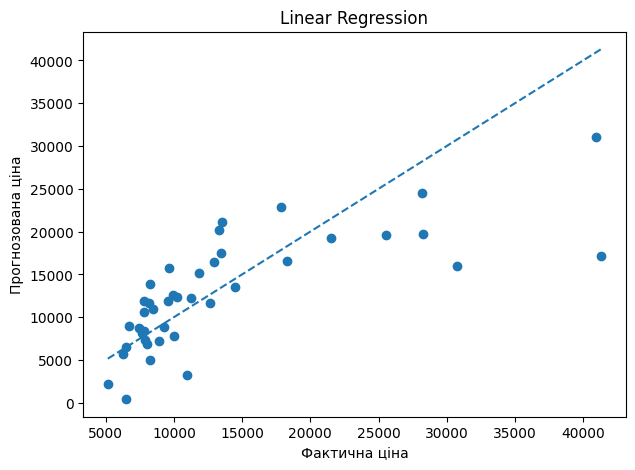

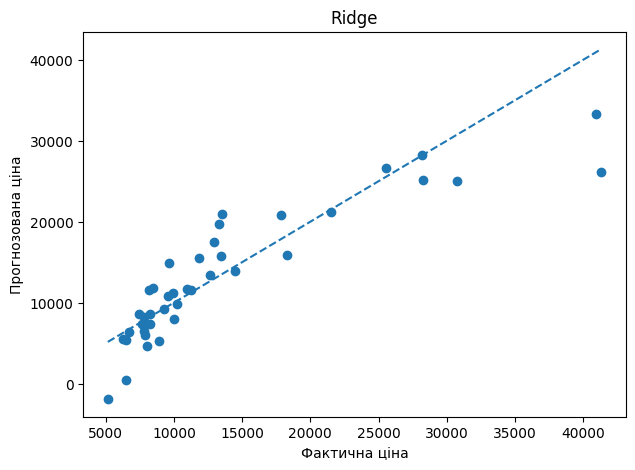

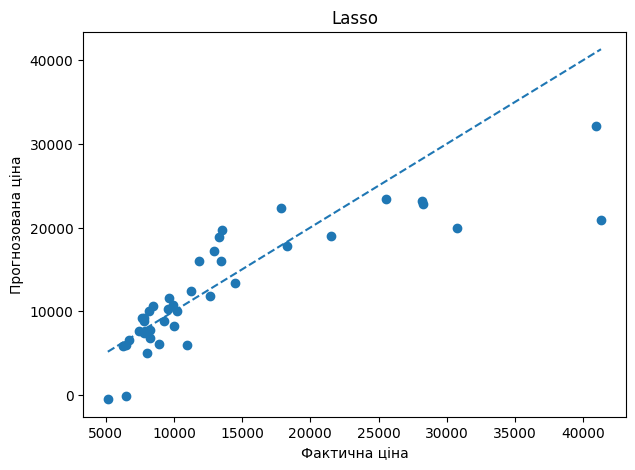

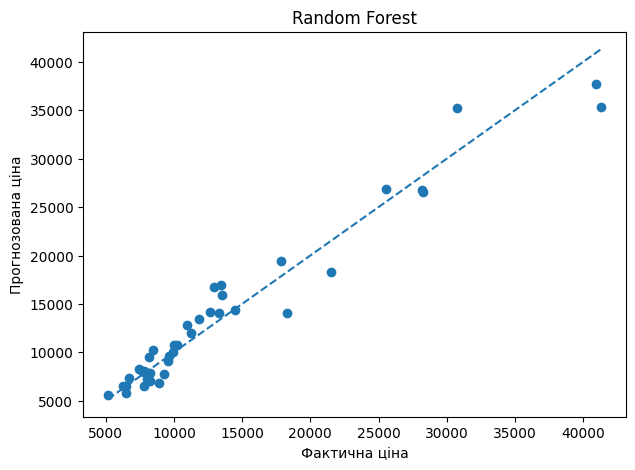

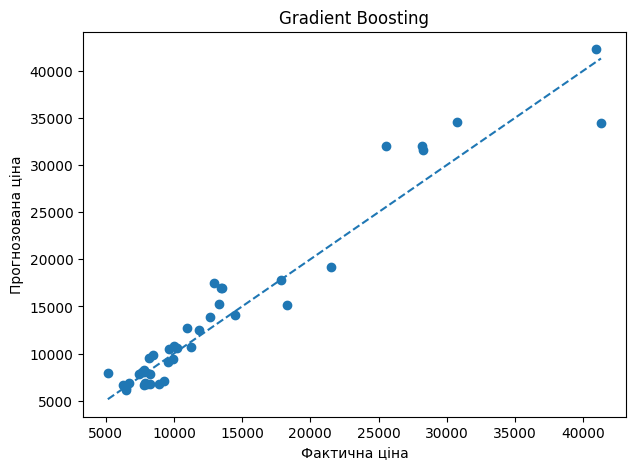

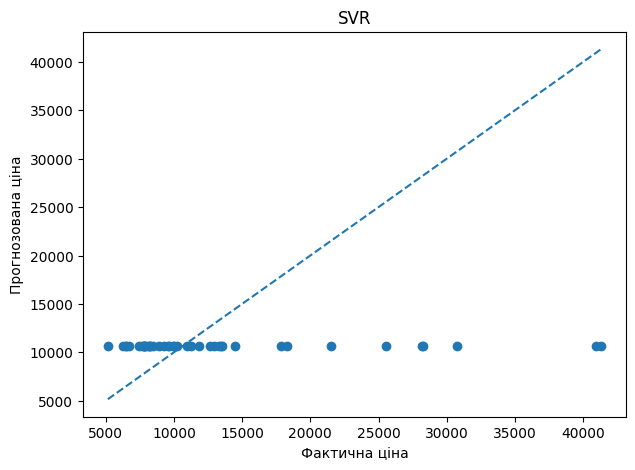

In [33]:
for name, y_pred in predictions.items():
    plt.figure(figsize=(7, 5))

    plt.scatter(y_test, y_pred)

    plt.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        linestyle="--"
    )

    plt.xlabel("Фактична ціна")
    plt.ylabel("Прогнозована ціна")
    plt.title(name)

    plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [35]:
sample_indices = X_test_selected.sample(
    10,
    random_state=42
).index

rf_predictions = models["Random Forest"].predict(
    X_test_selected.loc[sample_indices]
)

In [36]:
cars_10 = pd.DataFrame({
    "car_ID": id_test.loc[sample_indices].values,
    "Actual_Price": y_test.loc[sample_indices].values,
    "Predicted_Price": rf_predictions
})

In [37]:
cars_10["Absolute_Error"] = abs(
    cars_10["Actual_Price"] -
    cars_10["Predicted_Price"]
)

cars_10["Absolute_Percentage_Error"] = (
    cars_10["Absolute_Error"] /
    cars_10["Actual_Price"] * 100
)

cars_10

,car_ID,Actual_Price,Predicted_Price,Absolute_Error,Absolute_Percentage_Error
0,26,6692.0,7298.805,606.805,9.067618
1,176,9988.0,10798.650,810.650,8.116239
2,148,10198.0,10714.570,516.570,5.065405
3,17,41315.0,35310.690,6004.310,14.533003
4,69,28248.0,26595.285,1652.715,5.850733
5,147,7463.0,8230.000,767.000,10.277368
6,144,9960.0,10065.200,105.200,1.056225
7,85,14489.0,14346.480,142.520,0.983643
8,195,12940.0,16765.650,3825.650,29.564529
9,160,7788.0,7995.560,207.560,2.665126


Для більшості з 10 випадково вибраних автомобілів модель Random Forest дала досить близькі до фактичних значень прогнози. Середня абсолютна відсоткова помилка для цієї вибірки становить приблизно 8.72%. Найменша помилка дорівнює близько 0.98%, а найбільша — 29.56% для автомобіля з car_ID = 195. Отже, модель у більшості випадків прогнозує ціну досить точно, хоча для окремих автомобілів можливі значно більші відхилення.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


У лабораторній роботі було виконано підготовку даних та побудовано шість регресійних моделей для прогнозування ціни автомобіля. Найкращу якість показала модель Random Forest з R² = 0.949, MAE = 1447.34 та MAPE = 10.36%. Другий результат отримано для Gradient Boosting з R² = 0.929, тоді як Ridge, Lasso та Linear Regression показали помітно нижчу точність. Найгірший результат продемонструвала модель SVR з від’ємним значенням R² = -0.100 та MAPE = 36.02%.

Графіки фактичних і прогнозованих значень підтвердили результати метрик: прогнози Random Forest найближче розташовані до лінії ідеального прогнозу. Для 10 випадково вибраних автомобілів середня абсолютна відсоткова помилка Random Forest становила приблизно 8.72%, хоча для окремого автомобіля вона досягла 29.56%. Суттєвих ознак перенавчання лише за тестовими метриками встановити неможливо, оскільки для цього необхідно додатково порівняти якість на train і test або використати крос-валідацію. Попередня обробка даних, зокрема обмеження викидів, відбір сильно корельованих ознак, Yeo–Johnson, масштабування та One-Hot Encoding, забезпечила однакову й коректну підготовку даних для порівняння всіх моделей. За отриманими результатами Random Forest є найбільш придатною моделлю для прогнозування ціни автомобіля на цьому наборі даних.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
